In [ ]:


'''
Assignment 1
Student Name: Aaron Baggot
Student Number: C22716399
TU856/4

This assignment builds on functions covered in the labs using Python and OpenCV [1], 
several options were tested, the most effective pipeline used the following steps:

Bilateral Filter:
Bilateral filter reduces speckle and patchy noise while keeping edges by weighting pixels 
by both spacial distance and intensity difference. 
Underwater images are often grainy and uneven, 
so this step smooths the water without blurring the outline of the shark[2].

Example: “den = cv.bilateralFilter(img, 7, 75, 75)”


CLAHE (Contrast Limited Adaptive Histogram Equalisation) on LAB L channel:
CLAHE is applied to the L (lightness) channel in LAB to boost local contrast while clipping large peaks so noise is not over-amplified. 
This works well on low-contrast underwater scenes and helps reveal body detail/stripes implemented with “cv.createCLAHE().apply()”.[3]

Example: “L2 = cv.createCLAHE(clipLimit=3.0, tileGridSize=(8,8)).apply(L)”

Light unsharp mask 
A small Gaussian blur and weighted add gently sharpen edges and recover definition lost after denoising/contrast steps, 
while keeping the image natural. In the Gaussian blur, pixels near the kernel centre have higher weight. 
Implemented with  “cv.GaussianBlur” “cv.addWeighted()"[4].

Example:  blur = cv.GaussianBlur(enh, (0,0), 1.0)
          enh  = cv.addWeighted(enh, 1.20, blur, -0.20, 0)

Otsu thresholding for segmentation
Otsu’s method chooses a binary threshold automatically. 
Two simple variants are used so the same code handles different images:

•	Underwater mode: Otsu on LAB-b (blue - yellow) combined with inverted HSV saturation to separate fish from open water.

•	Silhouette mode: Otsu on inverted grayscale for darker, 
    low-saturation shapes such as Shark 2. Implemented with cv.threshold( THRESH_OTSU)[5].

Example: _, mask = cv.threshold(inv, 0, 255, cv.THRESH_BINARY + cv.THRESH_OTSU)


Morphology and largest component
Closing fills small holes, opening removes specks, and a light dilate thickens thin masks. 
This produces a clean blob for cropping with minimal tuning “cv.morphologyEx, cv.dilate” [6].
After labeling, only the largest connected component is kept to remove pixels/bubbles "cv.connectedComponents(mask)"[7] 

Example: k = cv.getStructuringElement(cv.MORPH_ELLIPSE, (KSIZE, KSIZE))
         mask = cv.morphologyEx(mask, cv.MORPH_CLOSE, k, iterations = CLOSE_IT)
         num, labc = cv.connectedComponents(mask)


Rotate and crop 
For underwater images, the mask contour is straightened with a minimum-area rectangle 
and rotated to horizontal using (cv.minAreaRect, cv.getRotationMatrix2D). 
For normal photos tested using image of a cat in snow background, 
a simple axis-aligned bounding box is used to avoid wedge artefacts. 
A small padding is added so the subject is not clipped[8].

Example:
“rect  = cv.minAreaRect(cnt)
 M     = cv.getRotationMatrix2D((W//2, H//2), rect[-1], 1.0)
 I_rot = cv.warpAffine(img, M, (W, H))”

Minimal background 
Pixels in a thin border outside the mask are sampled, their channel-wise median is used as a flat background colour. 
This produces the clean, minimal background required[9].


Summary
The program takes one image set on a plain background and outputs an enhanced version clearer and centered on a plain background. 
Bilateral filter reduces noise while preserving the edge. 
Otsu threshold creates a foreground mask using colour cues for blue underwater scenes and inverted greyscale for silhouettes.
Small morphological operations clean the mask and the largest blob is kept. 
The subject is then rotated to horizontal for underwater images or box cropped for normal images, 
and placed on a solid background colour estimated from the image border. 
The pipeline stays short and uses only a few tuneable values from the labs.

References
[1]	J. Howse, P. Joshi, and M. Beyeler, OpenCV: computer vision projects with Python: get savvy with OpenCV and actualize cool computer vision applications, 
    1st ed. Packt Publishing Livery Place 35 Livery Street Birmingham B3 2PB, UK: Packt Publishing, 2016.
    
[2]	C. Tomasi and R. Manduchi, “Bilateral filtering for gray and color images,” in Sixth International Conference on Computer Vision, 
    Jan. 1998, pp. 839–846. doi: 10.1109/ICCV.1998.710815.
    
[3]	J. Wu, “Enhancing Object Sorting Under Low-Light Conditions with CLAHE, Gaussian Blur, ROI,
    and Custom PID on a Raspberry Pi Robotic Arm,” Appl. Comput. Eng., vol. 96, no. 1, pp. 93–98, Nov. 2024, doi: 10.54254/2755-2721/96/20241240.
    
[4]	S. Singh, R. Verma, and A. K. Singh, “Image filtration in Python using openCV,” 
    Turk. J. Comput. Math. Educ., vol. 12, no. 6, pp. 5136–5143, 2021.
    
[5]	M. Huang, W. Yu, and D. Zhu, “An Improved Image Segmentation Algorithm Based on the Otsu Method,” in 2012 13th ACIS International Conference on Software Engineering, 
    Artificial Intelligence, Networking and Parallel/Distributed Computing, Aug. 2012, pp. 135–139. doi: 10.1109/SNPD.2012.26.
    
[6]	J. Jenrette, Z. Y.-C. Liu, P. Chimote, T. Hastie, E. Fox, and F. Ferretti, “Shark detection and classification with machine learning,” 
    Ecol. Inform., vol. 69, p. 101673, July 2022, doi: 10.1016/j.ecoinf.2022.101673.
    
[7]	F. Bolelli, S. Allegretti, and C. Grana, “Quest for Speed: The Epic Saga of Record-Breaking on OpenCV Connected Components Extraction”.

[8]	A. Mordvintsev, “OpenCV-Python Tutorials Documentation”.

[9]	A. P. Athane and D. S. R. Prasad, “Image Enhancement Based on Opencv Using Python 2.7 – Review,” vol. 8, no. 5, 2021.


'''

[OK] wrote: /Users/aaronbaggot/Desktop/Image_Processing_Assignment_1/outputs/final.png | mode = underwater, rotate = True, area = 0.619


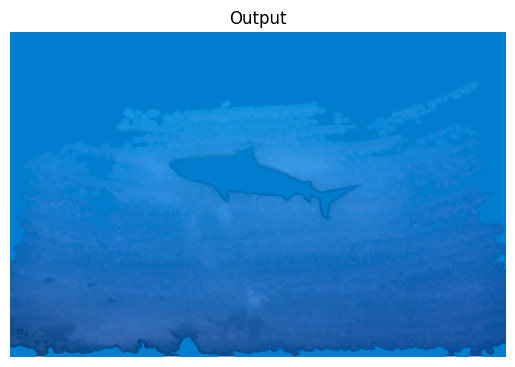

In [4]:
from pathlib import Path
import cv2 as cv
import numpy as np
import os
import matplotlib.pyplot as plt

# PARAMS
INPUT_PATH  = Path("data/raw/Shark 2.PNG")   # change for Shark 2 or Shark 1
MODE   = "underwater"    # "underwater" or "silhouette"
ROTATE = True            # False for cat
CLAHE_CLIP = 3.0
KSIZE      = 5
CLOSE_IT   = 1
DILATE_IT  = 2
PAD_FRAC   = 0.15

# ensure project root
here = Path.cwd()
if not (here/"data"/"raw").exists():
    for _ in range(4):
        if (here.parent/"data"/"raw").exists():
            os.chdir(str(here.parent)); break
        here = here.parent

def process_image(inp: Path):
    I = cv.imread(str(inp), cv.IMREAD_COLOR)
    if I is None:
        raise FileNotFoundError(inp)
    H, W = I.shape[:2]

    den = cv.bilateralFilter(I, 7, 75, 75)
    L,A,B = cv.split(cv.cvtColor(den, cv.COLOR_BGR2LAB))
    L2 = cv.createCLAHE(clipLimit = CLAHE_CLIP, tileGridSize=(8,8)).apply(L)
    enh = cv.cvtColor(cv.merge([L2, A, B]), cv.COLOR_LAB2BGR)
    blur = cv.GaussianBlur(enh, (0,0), 1.0)
    enh  = cv.addWeighted(enh, 1.20, blur, -0.20, 0)

    if MODE == "underwater":
        lab = cv.cvtColor(enh, cv.COLOR_BGR2LAB); _,_,b = cv.split(lab)
        hsv = cv.cvtColor(enh, cv.COLOR_BGR2HSV); S    = hsv[:,:,1]
        _, th_b  = cv.threshold(b,       0, 255, cv.THRESH_BINARY+cv.THRESH_OTSU)
        _, s_inv = cv.threshold(255 - S, 0, 255, cv.THRESH_BINARY+cv.THRESH_OTSU)
        mask = cv.bitwise_and(th_b, s_inv)
        if (mask.sum()/255)/mask.size < 0.03:
            mask = cv.bitwise_or(th_b, s_inv)
    else:
        g  = cv.cvtColor(enh, cv.COLOR_BGR2GRAY)
        gb = cv.GaussianBlur(g, (5,5), 0)
        inv = cv.normalize(255 - gb, None, 0, 255, cv.NORM_MINMAX)
        _, mask = cv.threshold(inv, 0, 255, cv.THRESH_BINARY+cv.THRESH_OTSU)

    k = cv.getStructuringElement(cv.MORPH_ELLIPSE, (KSIZE, KSIZE))
    mask = cv.morphologyEx(mask, cv.MORPH_CLOSE, k, iterations=CLOSE_IT)
    mask = cv.morphologyEx(mask, cv.MORPH_OPEN,  k, iterations=1)
    if DILATE_IT > 0:
        mask = cv.dilate(mask, k, iterations=DILATE_IT)

    num, labc = cv.connectedComponents(mask)
    if num > 1:
        areas = [(labc == i).sum() for i in range(1, num)]
        mask  = (labc == (1+int(np.argmax(areas)))).astype(np.uint8) * 255

    area = (mask.sum()/255)/mask.size
    if area < 0.005 or area > 0.98:
        return enh

    if ROTATE:
        cnts,_ = cv.findContours(mask, cv.RETR_EXTERNAL, cv.CHAIN_APPROX_SIMPLE)
        cnt  = max(cnts, key=cv.contourArea)
        rect = cv.minAreaRect(cnt); angle = rect[-1]; (rw,rh) = rect[1]
        if rw < rh: angle += 90
        if angle < -45: angle += 90
        M = cv.getRotationMatrix2D((W//2, H//2), angle, 1.0)
        I_r = cv.warpAffine(enh,  M, (W,H), flags  cv.INTER_LINEAR,  borderMode = cv.BORDER_REFLECT)
        m_r = cv.warpAffine(mask, M, (W,H), flags = cv.INTER_NEAREST, borderMode = cv.BORDER_CONSTANT)
        cnt_t = cv.transform(cnt.reshape(-1,1,2).astype(np.float32), M).astype(np.int32)
        x,y,w,h = cv.boundingRect(cnt_t)
    else:
        cnts,_ = cv.findContours(mask, cv.RETR_EXTERNAL, cv.CHAIN_APPROX_SIMPLE)
        x,y,w,h = cv.boundingRect(max(cnts, key = cv.contourArea))
        I_r, m_r = enh, mask

    pad = int(PAD_FRAC*min(W,H))
    x0 = max(0, x-pad); y0 = max(0, y-pad)
    x1 = min(W, x+w+pad); y1 = min(H, y+h+pad)
    crop = I_r[y0:y1, x0:x1]
    mcrp = m_r[y0:y1, x0:x1]

    inv = (mcrp == 0).astype(np.uint8)*255
    border = np.zeros_like(inv)
    border[:10,:] = 255; border[-10:,:] = 255
    border[:,:10] = 255; border[:,-10:] = 255
    samples = cv.bitwise_and(crop, crop, mask=cv.bitwise_and(inv, border)).reshape(-1,3)
    samples = samples[(samples.sum(1)>0)]
    bg = (210,220,230) if len(samples)==0 else tuple(map(int, np.median(samples,0)))
    canvas = np.full_like(crop, bg, dtype=np.uint8)
    final  = cv.add(cv.bitwise_and(crop,  crop,  mask=mcrp),
                    cv.bitwise_and(canvas, canvas, mask=cv.bitwise_not(mcrp)))

    return final

final_img = process_image(INPUT_PATH)
plt.imshow(cv.cvtColor(final_img, cv.COLOR_BGR2RGB))
plt.axis("off")
plt.title("Output")
plt.show()